In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import pandas as pd
from scipy.interpolate import interp1d
import scipy
import math
from scipy.special import factorial
import os
import astropy.units as u
import mhealpy as mh
import healpy as hp
from astropy.coordinates import SkyCoord

import astropy.units as u
import astropy.cosmology as acosmo
from astropy.coordinates import SkyCoord, EarthLocation, AltAz

#kafka stream alerts
from hop import Stream
from hop.io import StartPosition
sys.path.insert(1, '../') 
from ic_visualization import plot_IC_alert, write_new_yaml, plot_zoomed_IC_alert, select_pixels, check_source_in_map,
from params import p

/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


Given the detection of a neutrino  $\nu = \{E_\nu, t_\nu, \omega_\nu, s_\nu\}$ and the $N_j$ sources inside the neutrino's 90% probability region, we will  compute the bayesian ratio of the probability that  the neutrino is coming  from source $\xi_j$ versus  if its a background  alert:

$$
O = \frac{H_s}{H_0} = \frac{p_{temp}\cdot p_{spatial}\cdot p_{astro} \cdot p_{emission}(\xi_j)}{p_{emission}(B)}
$$

Let's get the effective area

In [2]:
with open('../IC_effective_area/Effa_all_streams_gold_bronze.txt',  'r') as file:
    table  = pd.read_table(file)

In [3]:
table.keys()

Index(['#E ', ' 30-90 ', ' 0-30 ', ' -5-0 ', ' -30--5 ', ' -90--30'], dtype='object')

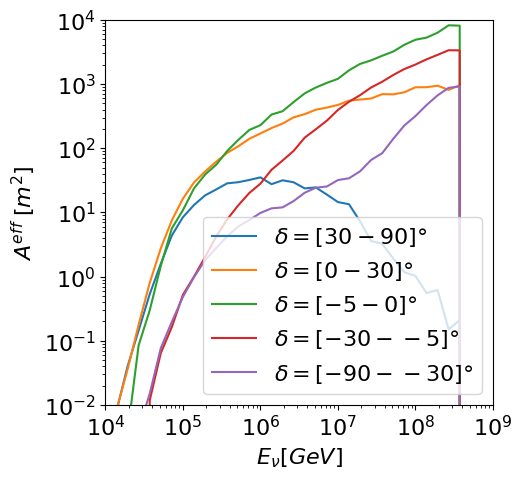

In [4]:
fig = plt.figure(figsize=(5,5))
for key in table.keys()[1:]:
    plt.plot(table['#E '], table[key], label=fr'$\delta=[{key}]\degree$')
    
plt.xscale('log')
plt.yscale('log')
plt.xlim(1e4, 1e9)
plt.ylim(1e-2, 1e4)
plt.xlabel(r'$E_\nu[GeV]$',  fontsize=16)
plt.ylabel(r'$A^{eff}\;[m^2]$',  fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.show()
    

In [5]:
def effective_area(E_nu, dec):
    if -90 <= dec <= -30:
        area_values = table[' -90- -30 '].values
    elif  -30 <= dec <= -5:
        area_values = table[' -30- -5 '].values
    elif -5 <= dec <= 0:
        area_values = table[' -5-0 '].values
    elif 0 <= dec <= 30:
        area_values = table[' 0-30 '].values
    elif 30 <= dec <= 90:
        area_values = table[' 30-90 '].values

    f = interp1d(table["#E "].values, area_values)
    return f(E_nu)  *u.m ** 2

### Neutrino Luminosities
From our computations in mathematica:
$$
L_{CC} = 10^{50}\;[\#\nu]
$$
Then, the emission  probability for a source $\xi_j$ assuming its of  type $k$ would be given by:

$$
p_{emiss}(\nu|\xi_j,k) = Poiss(N_\nu=1, \,\hat n_{j,k}) = \hat n_{j,k}e^{\hat  n_{j,k}}
$$

A source of $z=0.1$ will have a luminosity distance of:

$$D_L = 477.522\;[\text{Mpc}] \approx 1.47\times10^{22}\;[\text{m}]$$

Which if we assume its a core-collapse supernovae will have an emission of:


In [6]:
L_cc =  1e46 * (u.s ** -1 )
t_cc = (40 * u.d).to('s')
d = 1.47e25 * u.m
A_eff = effective_area(1e5, 30) * u.m ** 2
print(L_cc * t_cc / (4 * np.pi * d**2)*A_eff)


208.97935108137412 m2


In [7]:
def n_jk(L_k, d, A_eff):

    '''
    L_k: N of neutrinos, unitless
    d: distanc to source, in m
    A_eff: IceCube's effective area, in m^2
    '''
    

    return A_eff * L_k / (4 * np.pi * d  ** 2)

In [8]:
E_nu = 100 *  10**3  #GeV
A_eff = effective_area(E_nu, 25)
print('A_eff = ', A_eff)
hat_n_jk = n_jk(L_cc*t_cc, d, A_eff)
print('Expected detected neutrinos =  ', hat_n_jk)


A_eff =  16.420038686002147 m2
Expected detected neutrinos =   208.97935108137412


In [9]:
def emission_prob(N_nu, n_jk):

    '''
    Poission probability of detecting N_nu neutrinos
    '''
    return n_jk ** N_nu * np.exp(n_jk) / factorial(N_nu)

In [10]:
emission_prob(1,  hat_n_jk)

<Quantity 1.19862238e+93>

Now, the expected number of background alerts I would expect in the search region would be:
$$
\hat n_{B} = \phi_B\cdot A_{90} \cdot \Delta t_k
$$
Where on average the number of alertsis 26.8 per year. Then, $\phi_B = 26.8 / 4\pi / year = 1.7\times 10^{-6}\;[\deg^{-2}\,days^{-1}]$.

In [11]:
def bkg_prob(A_90, delta_t, b_flux=1.7e-6, N_nu=1):
    '''
    Params:
    -------
    A_90: float, area of the 90% containment region in square degrees. 
    delta_T: float, observing time window in days. Corresponds to the maximum time from the explosion 
            where we would expect a neutrino emission
    b_flux: float, bkg flux per square degree per days.
    N_nu:  int. number of detected  neutrinos. Usually its 1, but its a parameter in case we want  to test for a source  
            with multiple neutrinos
    '''
    n_b= b_flux * A_90 * delta_t

    #we return the poisson probability
    return n_b ** N_nu * np.exp(n_b)
    


    

In [12]:
print(bkg_prob(1, 40))

6.800462415721957e-05


Let's compute the bayesian ratio for a source of probabilities:
$$
p_{astro} = 0.5
$$
$$
p_{spatial} = 0.3
$$
$$
p_{temp} = 1
$$
$$
z = 0.1
$$
$$
p(SN\,Ibc|\xi_j) = 0.7
$$


In [13]:
print(0.5 * 0.3 * 1 * 1.1 / 1e-5 * 0.2  * 1/0.7)

4714.285714285715


We will now compute the total number of sources  up to a  redshift with the function:
$$
N^{tot}(z) = \int_0^z\frac{R(z')}{1+z'}\frac{dV}{dz'}dz'
$$

In [14]:
params = {
    'c': 299792.458, #km/s
    'h0': 67.4, #km/s/Mpc
    'omega_M': 0.315, 
    'omega_K': 0,
    'omega_L': 0.685,
    'z_min': 1e-4, # minimum redshift for integrating
    'N_int_steps': 1000000
}
def E_z(z, p=params):
    return np.sqrt(p['omega_M'] * (1 + z) ** 3 + p['omega_K'] * (1 + z) ** 2 + p['omega_L'])

def D_C(z, p=params):
    '''
    *** TO DO: compare  to known values ****
    
    Computes de comoving distance of a source at a redshift z assuming some cosmological model. 
    Params:
    -------
    z: float, redshift
    p: dict, general parameters parameters. 
    '''

    z_range, step = np.linspace(p['z_min'], z, p['N_int_steps'], retstep=True)

    hubble_dist = p['c'] / p['h0']

    invserse_E_z = 1 / E_z(z_range, p=p)

    distance = hubble_dist * scipy.integrate.trapezoid(invserse_E_z, z_range, dx=step)
    return distance

def D_L(z, p=params):
    '''
    Computes the luminosity distance, which in omega_K=0 itsjust (1+z) * D_C
    '''
    return (1 + z) * D_C(z, p=p)
    


def dVdz(z, p=params):
    '''
    *** TO DO: does my co-moving element need to have the luminosity distance? **
    
    Computes the comoving volume element at a given redshift. 
    '''

    hubble_dist = p['c'] / p['h0']
    
    return hubble_dist *  D_C(z, p=p) ** 2 / E_z(z, p=p) * 4 * np.pi



Now let's define the rate functions

In [15]:
def R_madau(z, R0):
    '''
    Volumetric rate as a function fo redshift ussing the approximation from Madau++?
    '''
    if type(z) == float or type(z) == int:
        if z <= 2:
            return R0 * (1 + z) ** 2.7
        else:
            return R0 * (1 + z) ** -2.9

    elif type(z) == np.ndarray: 
        return R0 * ((1 + z) ** 2.7 * (z<=2) + (1 + z) ** -2.9 * (z > 2))
    else:
        raise ValueError('Wrong input in the Rate function')

def N_nu(R_z, z, R0, p=params):
    '''
    Computes the total number of sources up to a redshift z

    Params:
    -------
    R_z: function, rate function assumed for the computation. It needs the params z, R0
    z: float, redshift up until we integrate
    R0: float
    '''

    z_range, steps = np.linspace(p['z_min'], z, p['N_int_steps'], retstep=True)

    y = R_z(z_range, R0) * dVdz(z_range, p=p) / (1 + z_range)

    return scipy.integrate.trapezoid(y, z_range, dx=steps)

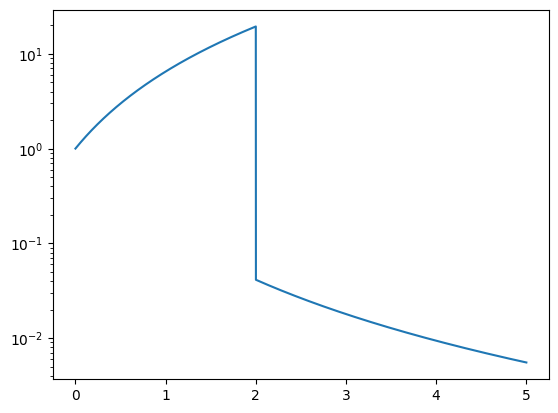

In [16]:
z_range = np.linspace(1e-4, 5, params['N_int_steps'])

plt.plot(z_range, R_madau(z_range, 1))
plt.yscale('log')
# plt.ylim(1e11, 8e11)
plt.show()

In [17]:
# R_CC =  10.1 * 10 ** 4 * 10 **  -9 #Mpc^-3 yr^-1
# plt.plot(z_range, N_nu(R_madau, z_range, R_CC))
# plt.yscale('log')
# plt.show()

In [18]:
z = np.linspace(1, 4, 50)
(z<=2) * 1 + (z > 2) * 2
type(z)

numpy.ndarray

In [19]:
R_CC =  10.1 * 10 ** -5 #Mpc^-3 yr^-1
# z = np.linspace(1, 5, 200)
# y = []
# for z_i in z:
#     y.append(N_nu(R_madau, z_i, R_CC))
# plt.plot(z, y)
# plt.yscale('log')
# plt.show()


We assume that a source class contributes a fraction $\lambda$ to the diffuse neutrino flux at a certain  energy $E$:
$$
F^{tot}_k(E_nu) = \lambda_k\cdot\phi_\nu E_\nu = \int_0^\infty\frac{L_k}{4\pi D_L(z')^2}\frac{R(z')}{1+z'}\frac{dV}{dz'}dz'
$$

From which we can obtain an average neutrino contribution per source class:
$$
L_k = \lambda_k \cdot \frac{\phi_\nu E_\nu}{\int_0^\infty\frac{1}{4\pi D_L(z')^2}\frac{R(z')}{1+z'}\frac{dV}{dz'}dz'} 
$$

In [20]:
def L_k(R_z, R_0, lambda_k, nu_flux, p=params, z_max=6):

    z_range, steps = np.linspace(p['z_min'], z_max, p['N_int_steps'], retstep=True)
    y = 1 / (4 * np.pi * D_L(z_range, p=p) ** 2)* R_z(z_range, R_0) / (1 + z_range)  * dVdz(z_range, p=p)

    return lambda_k * nu_flux * 4 * np.pi / scipy.integrate.trapezoid(y, z_range)

In [21]:
params
z_range =  np.linspace(params['z_min'], 5, 1000000)
nu_flux = 2.43e50
R_CC =  10.1 * 10 ** -5 #Mpc^-3 yr^-1
def R_madau(z):
    return 0.0068*0.0015*(1 + z)**2.7/(1 + ((1 + z)/2.9)**5.6)
# def y(z):
     
#     y = 1 / (4 * np.pi * D_L(z, p=params) ** 2)* R_madau(z) / (1 + z)
#     print('integral: ', scipy.integrate.trapezoid(y, z_range))
#     return  y

# plt.plot(z_range, y(z_range))
# plt.xscale('log')
# plt.yscale('log')
# plt.show()

In [22]:
nu_flux = 2.43e50
# L_k(R_madau, R_CC, 0.1, nu_flux, z_max=0.1)

In [23]:
# plt.plot(z_range, 1/(4*np.pi * D_L(z_range) ** 2))

In [24]:
p=params
# z_range, step = np.linspace(1, 2, p['N_int_steps'], retstep=True)
# y = 1 / (4 * np.pi * D_L(z_range, p=p) ** 2) * R_z(z_range, R_0) / (1 + z_range) * dVdz(z_range, p=p)
# y = 1 / (4 * np.pi * D_L(z_range, p=p) ** 2) * R_madau(z_range, R_CC)

In [25]:
 # 1 / (4 * np.pi * D_L(0.001, p=p) ** 2)

## Transient selection for the example
We will use AmpelAccess to select a few  sources to compute their  probabilities. I will just take ~10 objects from the latest alerts, give them  random spatial probabilities between  0.1-0.5, and choose $p_{temp}=1$. This would be the sources that pass the timing filter criteria. 

In [26]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Wswiglal-redir-stdio")

from pathlib import Path

import sys
sys.path.insert(1, '/Users/cristozilleruelo/Ampel-Access')
from ampel_report_tools import AmpelReportSet
from icecube_tools import IceCubeAlert, iter_icecube_public_alerts, convert_txt_alerts_to_fits, load_icecube_skymaps



In [27]:
CACHE_ROOT = Path("/Users/cristozilleruelo/Ampel-Access/cache_ampelaccess")

# if (CACHE_ROOT / "objects").exists():
#     ars = AmpelReportSet.load_cache(CACHE_ROOT)
#     print(f"Loaded cache: {len(ars)} objects")
# else:
#     ars = AmpelReportSet()
#     CACHE_ROOT.mkdir(parents=True, exist_ok=True)
#     print("No cache yet, starting fresh")


In [28]:
ars = AmpelReportSet()
host = 'kafka://kafka.scimma.org/'
topic = 'ampel.lsst.extragalactic-transients'
topic_url = f"{host}{topic}"
# group_id = "<Hopskotch_credential_name>-<unique_suffix>" #Unique-suffix can be anything
group_id = "cristobal.zilleruelo.canas-dba20fac-1"

stats = ars.update_from_stream(
    topic_url=topic_url,
    cache_root=CACHE_ROOT,
    group_id=group_id,
    start_at_if_new="EARLIEST",
    max_messages=None,
    persist=True,
)

print(stats)
ars.print_status()

{'n_messages': 65, 'n_objects_added': 17, 'n_objects_updated': 48, 'n_objects_total': 17}
AmpelReportSet status: 17 active / 17 total reports


/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


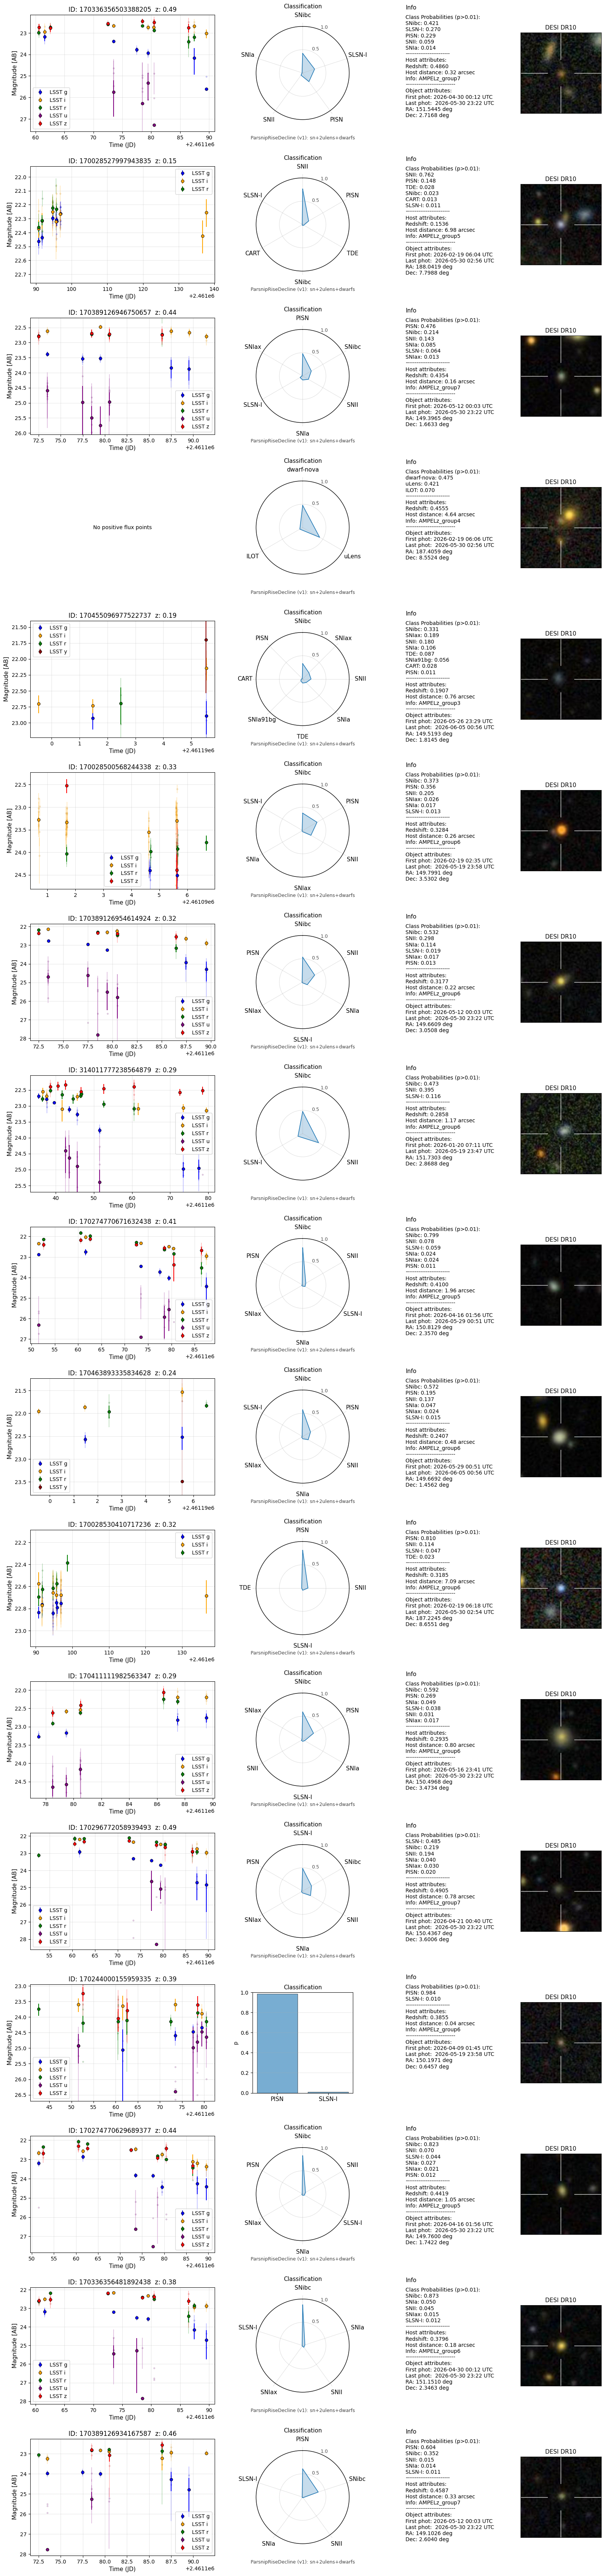

In [29]:
classifier = 0
model = 0
_ = ars.plot_summary_rows(classifier=classifier, model=model)

In [30]:
report=ars.active_reports[0]
vector = report.inspect(snr_limit=5.0, cls_threshold=0.00) 


Top-level keys (6): classification, features, host, object, photometry, state
Object: id=170336356503388205  external_id=None
  RA/Dec: 151.54451, 2.71682 deg
Photometry: 66 pts  bands=['lsstg', 'lssti', 'lsstr', 'lsstu', 'lsstz']
  time: 2026-04-30 00:12 .. 2026-05-30 23:22 UTC
  detections (SNR≥5): 36  by band: {'lsstg': 6, 'lssti': 11, 'lsstr': 12, 'lsstu': 0, 'lsstz': 7}
Classification [0]: ParsnipRiseDecline (v1)  info='Trained on ELAsTiCC'
  Model (0): sn+2ulens+dwarfs
    SNibc         p=0.421
    SLSN-I        p=0.270
    PISN          p=0.229
    SNII          p=0.059
    SNIa          p=0.014
    SNIax         p=0.004
    TDE           p=0.002
    CART          p=0.001
    SNIa91bg      p=0.000
    ILOT          p=0.000
    KN            p=0.000
    uLens         p=0.000
    Mdwarf-flare  p=0.000
    dwarf-nova    p=0.000
Host:
  z = 0.4860
  distance = 0.32 arcsec
  info: 'AMPELz_group7'


In [31]:
print(vector.keys())

dict_keys(['object', 'photometry', 'classifications', 'host'])


In [32]:
vector['classifications'][0]['models'][0]['probs']

{'P(CART)': 0.0009740891107217883,
 'P(ILOT)': 0.00021310082350414948,
 'P(KN)': 0.00012851617774201104,
 'P(Mdwarf-flare)': 8.861857953053342e-05,
 'P(PISN)': 0.2290089972694649,
 'P(SLSN-I)': 0.2696776891287564,
 'P(SNII)': 0.05856319935069075,
 'P(SNIa)': 0.014215395729345895,
 'P(SNIa91bg)': 0.00031088547853761736,
 'P(SNIax)': 0.0037416736557554925,
 'P(SNibc)': 0.42065287060476403,
 'P(TDE)': 0.002217980644347336,
 'P(dwarf-nova)': 8.283965065892989e-05,
 'P(uLens)': 0.00012414379618018326}

In [33]:
vector['object']['dec']

2.7168151696143363

In [ ]:
transient_times = {
    'SNibc': 20,
    'SNII': 100,
    'TDE': 365,
    'KN': 10,
}
transient_emissions = {
    'SNibc': 5.02216883514063e+30,
    'SNII': 5.02216883514063e+30,
    'TDE': 3.4076010291296514e+33,
    'KN': 6.253210311418056e+34
}

In [35]:
class Transient:
    
    def __init__(self, source_properties, neutrino_properties, transient_times=transient_times, 
                 transient_emissions=transient_emissions):
        
        self.classification = source_properties['classification'] #keys are formatted as p(k)
        self.z = source_properties['z']
        self.id = source_properties['id']
        self.spatial = np.random.uniform(0.1, 0.5)

        
        self.ra = np.random.uniform(neutrino_properties['ra'] -  neutrino_properties['ra_dec_err']/4,
                                   neutrino_properties['ra'] +  neutrino_properties['ra_dec_err']/4)
        self.ra = np.random.uniform(246.5, 247.5)
                                   #source_properties['ra']
        self.dec = np.random.uniform(neutrino_properties['dec'] -  neutrino_properties['ra_dec_err']/4,
                                   neutrino_properties['dec'] +  neutrino_properties['ra_dec_err']/4) #source_properties['dec']

        #neutrino properties
        self.signalness = neutrino_properties['signalness']
        self.A_90 = neutrino_properties['A_90'] #in deg^2
        self.alert_bkg_rate = neutrino_properties['bkg_rate'] #alerts / day / deg^-2
        self.E= neutrino_properties['E']
        self.m = neutrino_properties['m'] #halpix map

        self.A_eff = self.effective_area(self.E * 1e3, self.dec) #E in GeV, dec in deg

        #transient type properties
        self.transient_times = transient_times #in days
        self.transient_emissions = transient_emissions #number of  emitted neutrinos

        #probabilities we might use?
        self.n_bkg =  dict() #keys are the  transient type k
        self.n_jk = dict()
        self.weighted_n_jk = 0
        self.p_spatial = 0
        self.p_astro = self.signalness
        self.p_temp = 1

        
        #Now compute the base probabilities
        self.get_spatial_coincidence()
        for key in self.transient_times.keys():
            self.n_bkg[key] = self.get_n_bkg(key)
            self.n_jk[key] = self.get_njk(key)

        self.get_weighted_n_jk()
        


    def get_weighted_n_jk(self):
 
        for key in self.transient_times.keys():
            self.weighted_n_jk += self.classification[f'P({key})'] * self.n_jk[key]
             

    def get_likelihood_norm(self, total_n_jk):

        return self.p_astro * self.p_temp * self.p_spatial * self.weighted_n_jk / total_n_jk
    
    def Poiss(self, N_nu, n_jk):

        '''
        Poission probability of detecting N_nu neutrinos assuming a rate of n_jk
        '''
        return n_jk ** N_nu * np.exp(n_jk) / factorial(N_nu)
    

    def E_z(self, z, p=params):
        return np.sqrt(p['omega_M'] * (1 + z) ** 3 + p['omega_K'] * (1 + z) ** 2 + p['omega_L'])

    def D_C(self, z, p=params):
        '''
        *** TO DO: compare  to known values ****
        
        Computes de comoving distance of a source at a redshift z assuming some cosmological model. 
        Params:
        -------
        z: float, redshift
        p: dict, general parameters parameters. 
        '''
    
        z_range, step = np.linspace(p['z_min'], z, p['N_int_steps'], retstep=True)
    
        hubble_dist = p['c'] / p['h0']
    
        invserse_E_z = 1 / E_z(z_range, p=p)
    
        distance = hubble_dist * scipy.integrate.trapezoid(invserse_E_z, z_range, dx=step)
        return distance #Mpc?
    
    def D_L(self, z, p=params):
        '''
        Computes the luminosity distance, which in omega_K=0 itsjust (1+z) * D_C
        '''
        return (1 + z) * D_C(z, p=p)

    def effective_area(self, E_nu, dec):
        '''
        Effective area of the icecube dfetector for a neutrino of reconstructed energy E_nu at a certain declination/

        Params:
        ------
        E_nu: float, in GeV
        '''
        if -90 <= dec <= -30:
            area_values = table[' -90- -30 '].values
        elif  -30 <= dec <= -5:
            area_values = table[' -30- -5 '].values
        elif -5 <= dec <= 0:
            area_values = table[' -5-0 '].values
        elif 0 <= dec <= 30:
            area_values = table[' 0-30 '].values
        elif 30 <= dec <= 90:
            area_values = table[' 30-90 '].values
    
        f = interp1d(table["#E "].values, area_values)
        return f(E_nu)

    def get_n_bkg(self, k):
        
        n_bkg = self.alert_bkg_rate * self.transient_times[k] *  self.A_90 #[alerts]

        return n_bkg

    def get_bkg_poiss(self, k, N_nu=1):
        '''
        Computes the probability of observnig an coincidence alert in the same region as the sources. 
        We use the IceeCat-2 rate, 26.8 alerts/year as a "bakcground rate" and then compute the poission probability of observing 
        N_nu neutrinos there. 

        Params:
        -------
        N_nu: int, number of neutrinos detected
        k: str, type of transient assumed. k is a key in the dictionaries self.classification and in self.transient_times
        '''

        n_bkg = self.get_n_bkg(self, k)
        
        
        self.bkg_poiss = self.Poiss(N_nu, n_bkg)

        return self.bkg_poiss

    def get_njk(self, k):
        L_k = self.transient_emissions[k]
        d_j = self.D_L(self.z) * 3.086e22 #in m
        

        n_jk = L_k / (4 *  np.pi * d_j ** 2) * self.A_eff

        return n_jk
        
    def get_sig_poiss(self, k, N_nu=1):

        n_jk = self.get_njk(k)

        self.sig_poiss = self.Poiss(N_nu, n_jk)

        print('n_jk: ',  n_jk )
        print('z: ', self.z)
        
        return self.sig_poiss

    

    def get_bayes_ratio(self, k):

        bkg_poiss  = self.get_bkg_poiss(k)
        sig_poiss  = self.get_sig_poiss(k)

        return self.signalness * 1 * self.spatial * sig_poiss / bkg_poiss * self.classification[f'P({k})'] * 1/self.A_90

    def get_spatial_coincidence(self):
        
        '''
        Computes the spatial association probability
        '''
        psf = 0.1 #TODO
        # ra = self.ra * u.deg
        # dec = self.dec * u.deg
        # print('ra:  ', ra, ' dec: ', dec)
        prob_density_at_radec = self.m.get_interp_val(self.ra, self.dec, lonlat=True)

        self.p_spatial = prob_density_at_radec * psf
        print('p_spatial: ', self.p_spatial)

        return self.p_spatial

    
        
        
        

### Get latest kafka stream alert for testing
In principle this could also be done with the ICeCat-1, however on issue is that these alerts do  not come with the moc maps, so I don't know where to get the  area for this yet. I will  use the latest kafka alert instead.

In [36]:
#IceCat 1

# icecat1_path = '/Users/cristozilleruelo/Desktop/DESY/Thesis/IceCat-1/'
# alerts_path = os.path.join(icecat1_path,  'IceCube_Gold_Bronze_Tracks.csv')
# eff_areas_path = os.path.join(icecat1_path, 'eff_area', 'Effa_all_streams_gold_bronze.txt')
# with open(alerts_path, 'r') as file:
#     ic_alerts = pd.read_csv(file)

# #get effective areas:
# with open(eff_areas_path,  'r') as file:
#     eff_areas = pd.read_table(file)
# ic_alerts[['DEC', 'DEC_ERR_MINUS', 'DEC_ERR_PLUS', 'ENERGY', 'SIGNAL', 'FAR']]


#kafka stream

from hop import Stream
from hop.io import StartPosition
#https://hop-client.readthedocs.io/en/latest/user/quickstart.html

stream = Stream(start_at=StartPosition.EARLIEST, until_eos=True)
alerts = []
with stream.open("kafka://kafka.scimma.org/gcn.notices.icecube.gold_bronze_track_alerts", "r") as s:
    for message in s:
         # print(message.content)
        alerts.append(message.content)


latest alert: 


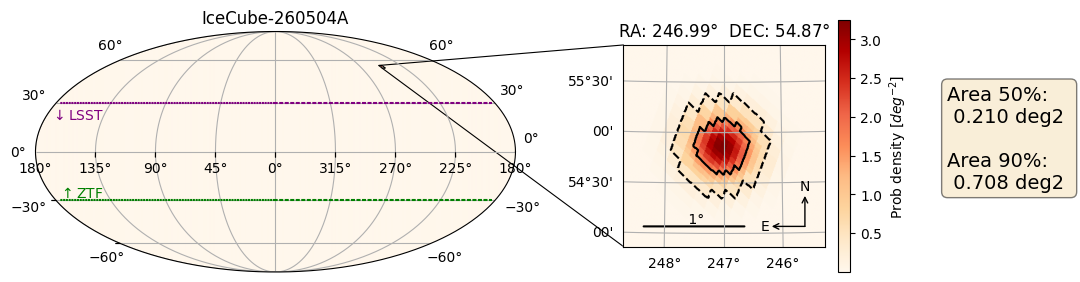

ra:   247.0 deg  dec:  55.0 deg


np.float64(2.6526742445163665)

In [37]:
print('latest alert: ')
ic_alert = alerts[-1]
map_path, A_90, m = plot_IC_alert(ic_alert['healpix_url'], r=1)
ic_alert

#TEST
ra = 247 * u.deg
dec = 55 * u.deg
print('ra:  ', ra, ' dec: ', dec)



m.get_interp_val(247, 55, lonlat=True)



In [38]:
help(m.get_interp_val)

Help on method get_interp_val in module mhealpy.containers.healpix_map:

get_interp_val(theta, phi=None, lonlat=False) method of mhealpy.containers.healpix_map.HealpixMap instance
    Return the bi-linear interpolation value of a map using 4 nearest neighbours.

    For MOC maps, this is equivalent to rasterizing the map first to the
    highest order.

    Args:
        theta (float, array or SkyCoord): Zenith angle (rad)
        phi (float or array): Azimuth angle (rad)

    Return:
        scalar or array



In [39]:
#IceCat-1
# test_alert = ic_alerts.iloc[2]
# print(test_alert)
# neutrino_properties = {
#     'signalness': test_alert['SIGNAL'],
#     'A_90': 0
# }

#kafka


neutrino_properties = {
    'signalness': ic_alert['p_astro'],
    'A_90': A_90.value,
    'bkg_rate': 28.6 / 365 / (4 * np.pi * (180/ np.pi) **2),
    'E': ic_alert['nu_energy'], #in TeV
    'ra': ic_alert['ra'],
    'dec': ic_alert['dec'],
    'ra_dec_err': ic_alert['ra_dec_error'],
    'm': m
    
}
sources = []
transients = []
n=0
for transient in ars.active_reports[:6]:
    n+=1
    vector = transient.inspect(snr_limit=5.0, cls_threshold=0.00)
    print("HERE: ", vector['classifications'][0]['models'][0]['probs'].keys())
    source_properties = {
        'classification': vector['classifications'][0]['models'][0]['probs'],
        'z': vector['host']['redshift'],
        'id': vector['object']['id'],
        'ra': vector['object']['ra'],
        'dec': vector['object']['dec'],
    }
    transients.append(Transient(source_properties, neutrino_properties))
    sources.append({
        'name': n,
        'ra': transients[-1].ra,
        'dec': transients[-1].dec
                   })



Top-level keys (6): classification, features, host, object, photometry, state
Object: id=170336356503388205  external_id=None
  RA/Dec: 151.54451, 2.71682 deg
Photometry: 66 pts  bands=['lsstg', 'lssti', 'lsstr', 'lsstu', 'lsstz']
  time: 2026-04-30 00:12 .. 2026-05-30 23:22 UTC
  detections (SNR≥5): 36  by band: {'lsstg': 6, 'lssti': 11, 'lsstr': 12, 'lsstu': 0, 'lsstz': 7}
Classification [0]: ParsnipRiseDecline (v1)  info='Trained on ELAsTiCC'
  Model (0): sn+2ulens+dwarfs
    SNibc         p=0.421
    SLSN-I        p=0.270
    PISN          p=0.229
    SNII          p=0.059
    SNIa          p=0.014
    SNIax         p=0.004
    TDE           p=0.002
    CART          p=0.001
    SNIa91bg      p=0.000
    ILOT          p=0.000
    KN            p=0.000
    uLens         p=0.000
    Mdwarf-flare  p=0.000
    dwarf-nova    p=0.000
Host:
  z = 0.4860
  distance = 0.32 arcsec
  info: 'AMPELz_group7'
HERE:  dict_keys(['P(CART)', 'P(ILOT)', 'P(KN)', 'P(Mdwarf-flare)', 'P(PISN)', 'P(SLSN-I

In [40]:
total_njk = 0
n_jk_dict = dict()
n_bkg_dict = dict()
for key in  transient_times.keys():
    n_bkg = transients[0].get_n_bkg(key)
    n_bkg_dict[key] = n_bkg
    n_jk_dict[key] = dict()
    print('\nAssuming  k = ', key, '-->  n_bkg = ', np.format_float_scientific(n_bkg), '\n')
    for  transient in transients:
        total_njk +=  transient.get_njk(key)
    for transient  in transients:
        n_jk = transient.get_njk(key) / total_njk
        n_jk_dict[key][transient.id] = n_jk
        print(transient.id, ' --> n_jk / tot_n_jk =  ', np.format_float_scientific(n_jk))


Assuming  k =  SNibc -->  n_bkg =  5.38029082833904e-05 

170336356503388205  --> n_jk / tot_n_jk =   3.5046865520139754e-02
170028527997943835  --> n_jk / tot_n_jk =   4.8776375384853193e-01
170389126946750657  --> n_jk / tot_n_jk =   4.552918921066056e-02
170028528399024209  --> n_jk / tot_n_jk =   4.090351588267882e-02
170455096977522737  --> n_jk / tot_n_jk =   3.0261941879457205e-01
170028500568244338  --> n_jk / tot_n_jk =   8.813725674341677e-02

Assuming  k =  TDE -->  n_bkg =  4.909515380859375e-04 

170336356503388205  --> n_jk / tot_n_jk =   3.432220587765789e-02
170028527997943835  --> n_jk / tot_n_jk =   4.7767832388971365e-01
170389126946750657  --> n_jk / tot_n_jk =   4.458778787601262e-02
170028528399024209  --> n_jk / tot_n_jk =   4.005775901524198e-02
170455096977522737  --> n_jk / tot_n_jk =   2.963621950292763e-01
170028500568244338  --> n_jk / tot_n_jk =   8.63148537406628e-02


In [41]:
total_njk = dict()
for transient_id in n_jk_dict[list(n_jk_dict.keys())[0]].keys():
    total_njk[transient_id] = 0
    for key in n_jk_dict.keys():
        total_njk[transient_id] += n_jk_dict[key][transient_id]
for transient in transients:
    # print("ID: ",  transient.id, ' p_astro: ', transient.signalness, ' p_spatial ', transient.p_spatial, ' p_temp ', transient.p_temp)
    # print(' total likelihood: ', total_njk[transient.id] * transient.p_spatial * transient.p_temp * transient.signalness)
    print('p_spatial: ', transient.p_spatial, ' total_likelihood: ', total_njk[transient.id] * transient.p_spatial * transient.p_temp * transient.signalness)

p_spatial:  0.2911976498002677  total_likelihood:  0.008692107573910186
p_spatial:  0.12483016611695932  total_likelihood:  0.051858161712840155
p_spatial:  0.10330442031098613  total_likelihood:  0.004005870138213828
p_spatial:  0.16792673558717325  total_likelihood:  0.005850170587891721
p_spatial:  0.15702985702659977  total_likelihood:  0.04047315618669209
p_spatial:  0.26405275433759384  total_likelihood:  0.0198215802856128



### Bayes Ratio
$$
O_{j,k} = \frac{H_s}{H_0} = \frac{p_{temp}\cdot p_{spatial}\cdot p_{astro} \cdot Poiss(1; \,n_{jk})}{Poiss(1;\,n_{bg})}\cdot\frac{\pi_s}{\pi_B}
$$

#### With
$$
n_{jk} = \frac{L_k}{4\pi d^{2}}\cdot A_{eff}(E_\nu,\delta_j)
$$

$$
n_{B} = \phi_B\cdot A_{90} \cdot \Delta t_k
$$

#### Priors:
$$
\pi_s = p(k|\xi_j) / A_{90}
$$

$$
\pi_b = 1
$$
Where on average the number of alertsis 26.8 per year. Then, $\phi_B = 26.8 / 4\pi / year = 1.7\times 10^{-6}\;[\deg^{-2}\,days^{-1}]$.


In [42]:

for key in  transient_times.keys():
    print('\nAssuming  k = ', key)#, '-->  Poiss(1, n_bkg) = ', np.format_float_scientific(transients[0].get_bkg_poiss(key)), '\n')
    n = 1
    for transient in transients[:6]:
        print(n, ' --> Odds ratio =  ', np.format_float_scientific(transient.get_bayes_ratio(key)))
        n+=1
        


Assuming  k =  SNibc


TypeError: Transient.get_n_bkg() takes 2 positional arguments but 3 were given

In [ ]:
_, A_90, m_prob = plot_IC_alert(ic_alert['healpix_url'], plot_source=sources, r=1, save_dir='/Users/cristozilleruelo/Desktop')

In [ ]:
#TO DO: read in probability form healpix map. ??
#Get cyan color sampler (or from another cmap?

In [ ]:
ra = 247 * u.deg
dec= 55 * u.deg
coords = SkyCoord(ra, dec, frame='icrs')

# 3. Evaluate the map
# MhealMap handles the multi-resolution lookup automatically
val = m_prob.get_interp_val(ra.to('rad').value, dec.to('rad').value, lonlat=True)
# val = hp.pixelfunc.get_interp_val(m_prob, ra, dec, lonlat=True, nest=True)

val

 ## ***** MAP IS NOT NORMALIZED CORRECTLY -> NEED TO CHECK ****

In [48]:
t_max = 10 ** 6.5 * u.s
t_max.to(u.d)

<Quantity 36.60043588 d>

In [49]:
t_max / 3600 / 24

<Quantity 36.60043588 s>